<a href="https://colab.research.google.com/github/isabellagarito/BioSense-AI/blob/student1-ecg/01_ecg_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student 1 — ECG Reliability

Responsável por ECG, detecção de HR, métricas de confiabilidade e avaliação de erro usando R-peaks como referência.

In [1]:
import os, sys, subprocess
from pathlib import Path
from google.colab import userdata

ORG = "isabellagarito"        # dono do repositório
REPO = "BioSense-AI"
BRANCH = "student1-ecg"
token = userdata.get("GITHUB_TOKEN")      # lido dos Secrets, nunca escreva o token aqui

if not os.path.isdir(f"/content/{REPO}"):
    !git clone -q https://{token}@github.com/{ORG}/{REPO}.git /content/{REPO}
os.chdir(f"/content/{REPO}")

!git config user.name "Seu Nome"
!git config user.email "seu-email-do-github@exemplo.com"
!git fetch -q origin
!git checkout {BRANCH} || git checkout -b {BRANCH}
!git pull -q --rebase origin {BRANCH} || true
!git branch --show-current

ROOT = Path(f"/content/{REPO}/student1_ecg")
FIG, OUT = ROOT / "figures", ROOT / "outputs"
sys.path.append(str(ROOT))


def salvar(msg):
    """git add + commit + pull --rebase + push da pasta student1_ecg."""
    for cmd in (["git", "add", "student1_ecg"],
                ["git", "commit", "-q", "-m", msg],
                ["git", "pull", "-q", "--rebase", "origin", BRANCH],
                ["git", "push", "-q", "-u", "origin", BRANCH]):
        r = subprocess.run(cmd, capture_output=True, text=True)
        print("$", " ".join(cmd[:2]), "->", "ok" if r.returncode == 0 else (r.stderr or r.stdout).strip())

Already on 'student1-ecg'
Your branch is behind 'origin/student1-ecg' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
student1-ecg


In [2]:
%pip install -q wfdb neurokit2

In [3]:
import wfdb, neurokit2 as nk, numpy as np, pandas as pd
print("wfdb", wfdb.__version__, "| neurokit2", nk.__version__)

wfdb 4.3.1 | neurokit2 0.3.0


In [4]:
import importlib.metadata as md
pk = ["wfdb", "neurokit2", "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "pyarrow"]
lines = [f"# Python {sys.version.split()[0]} (Google Colab)"] + [f"{p}=={md.version(p)}" for p in pk]
(ROOT / "requirements.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

# Python 3.13.18 (Google Colab)
wfdb==4.3.1
neurokit2==0.3.0
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
pyarrow==23.0.1


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

PN = "pulse-transit-time-ppg/1.1.0"
RECORDS = ["s1_sit", "s1_walk", "s1_run"]
print("wfdb:", wfdb.__version__, "| numpy:", np.__version__)

wfdb: 4.3.1 | numpy: 2.4.6


In [6]:
for name in RECORDS:
    h = wfdb.rdheader(name, pn_dir=PN)
    print(f"--- {name}")
    print("fs:", h.fs, "| amostras:", h.sig_len,
          "| duração (s):", round(h.sig_len / h.fs, 1))
    print("canais:", h.sig_name)
    print("unidades:", h.units)
    print("samps_per_frame:", h.samps_per_frame)
    print("comentários:", h.comments)

--- s1_sit
fs: 500 | amostras: 254026 | duração (s): 508.1
canais: ['ecg', 'pleth_1', 'pleth_2', 'pleth_3', 'pleth_4', 'pleth_5', 'pleth_6', 'lc_1', 'lc_2', 'temp_1', 'temp_2', 'temp_3', 'a_x', 'a_y', 'a_z', 'g_x', 'g_y', 'g_z']
unidades: ['mV', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'C', 'C', 'C', 'g', 'g', 'g', 'deg/s', 'deg/s', 'deg/s']
samps_per_frame: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
comentários: ['<filename>: s1_sit <activity>: sit <gender>: female <height>: 160 <weight>: 50 <age>: 25 <bp_sys_start>: 87 <bp_sys_end>: 87 <bp_dia_start>: 59 <bp_dia_end>: 57 <hr_1_start>: 74 <hr_2_start>: 69 <hr_1_end>: 74 <hr_2_end>: 70 <spo2_start>: 98 <spo2_end>: 98']
--- s1_walk
fs: 500 | amostras: 245902 | duração (s): 491.8
canais: ['ecg', 'pleth_1', 'pleth_2', 'pleth_3', 'pleth_4', 'pleth_5', 'pleth_6', 'lc_1', 'lc_2', 'temp_1', 'temp_2', 'temp_3', 'a_x', 'a_y', 'a_z', 'g_x', 'g_y', 'g_z']
unidades: ['mV', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'NU', 'C', 'C'

In [7]:
name = "s1_sit"
h = wfdb.rdheader(name, pn_dir=PN)
i = h.sig_name.index("ecg")            # índice do canal do ECG
rec = wfdb.rdrecord(name, pn_dir=PN, channels=[i])
ecg, fs = rec.p_signal[:, 0], rec.fs

ann = wfdb.rdann(name, "atr", pn_dir=PN)
ref = ann.sample / fs                  # instantes (s) dos R-peaks de referência
rr = np.diff(ref)

print("ECG:", ecg.shape, "| NaNs:", int(np.isnan(ecg).sum()))
print("anotações:", len(ann.sample), "| símbolos:", set(ann.symbol))
print("última anotação dentro do sinal?", ann.sample.max() < len(ecg))
print("RR (s) min/mediana/max:", rr.min().round(3), np.median(rr).round(3), rr.max().round(3))
print("HR de referência (bpm):", round(60 / np.median(rr), 1))

ECG: (254026,) | NaNs: 0
anotações: 613 | símbolos: {'N'}
última anotação dentro do sinal? True
RR (s) min/mediana/max: 0.672 0.83 0.956
HR de referência (bpm): 72.3


In [8]:
import re

comentario = " ".join(h.comments) # junta os comentários do header em uma única string

def extrair_hr(nome):
    resultado = re.search(rf"<{nome}>:\s*(\d+)", comentario)
    return int(resultado.group(1)) if resultado else None

hr_start = extrair_hr("hr_1_start") # frequências cardíacas registradas no header
hr_end = extrair_hr("hr_1_end")

hr_ref = 60 / np.median(rr) # frequência cardíaca calculada pelas anotações

print("\n--- Comparação de HR ---")
print(f"HR de referência (anotações): {hr_ref:.1f} BPM")
print(f"HR inicial (hr_1_start): {hr_start} BPM")
print(f"HR final (hr_1_end): {hr_end} BPM")

if hr_start is not None:
    print(f"Diferença inicial: {abs(hr_ref - hr_start):.1f} BPM")

if hr_end is not None:
    print(f"Diferença final: {abs(hr_ref - hr_end):.1f} BPM")


--- Comparação de HR ---
HR de referência (anotações): 72.3 BPM
HR inicial (hr_1_start): 74 BPM
HR final (hr_1_end): 74 BPM
Diferença inicial: 1.7 BPM
Diferença final: 1.7 BPM


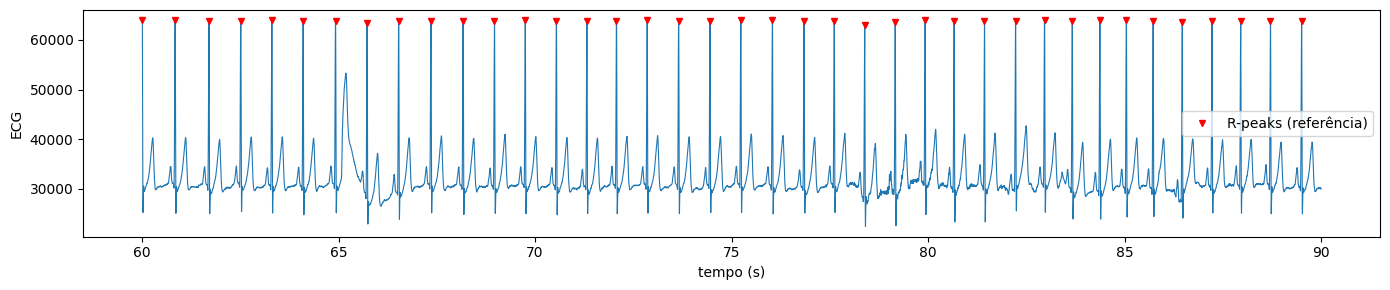

In [9]:
t = np.arange(len(ecg)) / fs
t0, t1 = 60, 90
m = (t >= t0) & (t < t1)
peaks = ann.sample[(ann.sample >= t0 * fs) & (ann.sample < t1 * fs)]

plt.figure(figsize=(14, 3))
plt.plot(t[m], ecg[m], lw=0.8)
plt.plot(peaks / fs, ecg[peaks], "rv", ms=5, label="R-peaks (referência)")
plt.xlabel("tempo (s)"); plt.ylabel("ECG")
plt.legend(); plt.tight_layout(); plt.show()

In [10]:
rows = []
for name in RECORDS:
    h = wfdb.rdheader(name, pn_dir=PN)
    i = h.sig_name.index("ecg")
    rec = wfdb.rdrecord(name, pn_dir=PN, channels=[i])
    ann = wfdb.rdann(name, "atr", pn_dir=PN)
    rr = np.diff(ann.sample) / rec.fs
    rows.append({
        "registro": name,
        "fs": rec.fs,
        "duracao_s": round(rec.sig_len / rec.fs, 1),
        "n_anotacoes": len(ann.sample),
        "hr_ref_mediana": round(60 / np.median(rr), 1),
        "rr_max_s": round(rr.max(), 2),
        "nans": int(np.isnan(rec.p_signal).sum()),
    })

audit = pd.DataFrame(rows)

OUT.mkdir(parents=True, exist_ok=True)
audit.to_csv(OUT / "audit_s1.csv", index=False)
audit

,registro,fs,duracao_s,n_anotacoes,hr_ref_mediana,rr_max_s,nans
0,s1_sit,500,508.1,613,72.3,0.96,0
1,s1_walk,500,491.8,767,93.5,0.75,0
2,s1_run,500,490.5,659,80.4,0.83,0


# **Notas da base — Pulse Transit Time PPG Dataset v1.1.0**

### **1. Características gerais**

A base **Pulse Transit Time PPG Dataset** contém registros fisiológicos de 22 sujeitos saudáveis, que realizaram três atividades físicas: sentado (*sit*), caminhada estacionária (*walk*) e corrida (*run*).

Ao todo, são **66 registros**, correspondentes a três atividades por participante. Os dados incluem sinais de ECG, PPG, pressão de contato dos sensores, temperatura, acelerômetro e giroscópio.&#x20;

README.txt



### **2. Amostragem e duração**

Os headers analisados apresentam frequência de amostragem (fs) de **500 Hz**. A duração varia entre os registros, ficando em torno de 8 minutos.

| Registro  | Duração | Amostras |
| --------- | ------- | -------- |
| s1_sit  | 508,1 s | 254.026  |
| s1_walk | 491,8 s | 245.902  |
| s1_run  | 490,5 s | 245.274  |

### **3. Canais e unidades**

O canal ECG está presente e foi identificado como `ecg`, com unidade **mV (milivolts)**, frequência de 500 Hz e samps_per_frame = 1.

As demais unidades identificadas nos headers são:

| Canais                             | Unidade |
| ---------------------------------- | ------- |
| PPG (pleth_1 a pleth_6)        | NU      |
| Pressão (lc_1, lc_2)           | NU      |
| Temperatura (temp_1 a temp_3)  | °C      |
| Acelerômetro (a_x, a_y, a_z) | g       |
| Giroscópio (g_x, g_y, g_z)   | deg/s   |

NU = unidades não especificadas (unidades arbitrárias).

**Observação:** os headers WFDB consultados apresentam 18 canais de sinais. O README também menciona 19 sinais e identifica peaks como uma coluna exclusiva do CSV, enquanto no WFDB os picos são armazenados nas anotações. Essa diferença deve ser considerada ao contabilizar os canais.
### **4. Anotações ECG (.atr)**

Os arquivos .atr contêm as anotações dos picos R do ECG. Segundo o README, esses picos foram detectados automaticamente e posteriormente verificados manualmente.

No registro s1_sit, foram encontrados 613 picos, todos com símbolo N, indicando batimentos normais. As anotações são utilizadas como referência oficial para avaliar os algoritmos de detecção.

### **5. Licença e tamanho**

A base utiliza a licença **Open Data Commons Open Database License (ODbL) v1.0** e possui aproximadamente **2,9 GB de dados descompactados**.&#x20;


## **Auditoria dos registros**

1\. **Taxa e duração:** os três registros apresentam frequência de amostragem de 500 Hz, com durações entre 490,5 e 508,1 segundos.

2\. **Canal e unidades:** o ECG está identificado como `ecg`, possui unidade mV e samps_per_frame = 1; os demais sensores utilizam unidades NU, °C, g e deg/s.

3\. **Anotações:** foram encontrados 613 picos R em s1_sit, 767 em s1_walk e 659 em s1_run; no registro s1_sit, todos os símbolos verificados foram N.

4\. **Frequência cardíaca de referência:** foram obtidos 72,3 BPM para sentado, 93,5 BPM para caminhada e 80,4 BPM para corrida, calculados pela mediana dos intervalos RR das anotações.

5\. **Integridade e observações:** nenhum valor NaN foi encontrado nos três sinais ECG analisados. Um resultado que merece investigação é a frequência cardíaca da caminhada ser maior que a da corrida; isso não significa necessariamente um erro nos dados.

### **6. Comparação com a frequência cardíaca do header**

Na comparação anteriormente realizada para s1_sit, temos:

 Medida           | Frequência cardíaca
 ---------------- | -------------------
 Anotações .atr | 72,3 BPM            
 hr_1_start     | 74 BPM              
 hr_1_end       | 74 BPM              

A diferença foi de apenas 1,7 BPM em relação a cada medida do header. Isso indica boa proximidade entre as referências, embora sejam medições realizadas em condições e momentos diferentes.

**Fonte oficial:** [PhysioNet — Pulse Transit Time PPG Dataset v1.1.0](https://physionet.org/content/pulse-transit-time-ppg/1.1.0/?utm_source=chatgpt.com).
